# GLD965: direct MA5 residual regression and direction classification

Five horizons, four chronological development folds. No untouched final holdout. All results use the saved source snapshot. Gain diversity is a separate requirement from skill. See Methodology and experiment.py for the complete reproducible training procedure.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
P=Path.cwd()
display(pd.read_csv(P/'Methodology.csv'))
display(pd.read_csv(P/'Snapshot.csv'))

,topic,description
0,Target,GLD965 15m; direct next MA5 at horizons 1..5 (...
1,Residual,u=(future MA5-structural baseline)/current clo...
2,Direction,future MA5 > current observed MA5; ties=0; pro...
3,Timing,Current completed own bar is allowed. Saved re...
4,Validation,"Four expanding folds, gap=30 context rows; com..."
5,Selection,Train-only null >=20% and zero variance remova...
6,Gain requirement,At least 4 features with >=5% of training tota...
7,Acceptance,"Paired circular 30-row block bootstrap, 1000 s..."
8,Model settings,"{""n_estimators"": 150, ""learning_rate"": 0.03, ""..."
9,Linear settings,"Ridge alpha=10, standardized X/Y; LogisticRegr..."


,rows,eligible,features,start,end,source,sha256
0,42803,38200,46,2024-12-31 17:15:00+00:00,2026-11-06 22:00:00+00:00,/workspace/tidewatch_wiki/research/mts_gold/tr...,32a54a7ea2346de99359c7347cd6f184ea3af23b828250...


## Reproduce training
The following callable retrains all fixed models and regenerates outputs. It is deliberately not invoked automatically when inspecting saved results.

In [2]:
from experiment import run
# results = run()  # Uncomment to retrain all folds/horizons.

In [3]:
display(pd.read_csv(P/'Fold_schedule.csv'))
display(pd.read_csv(P/'Feature_dictionary.csv'))
display(pd.read_csv(P/'Feature_quality.csv').groupby('fold').agg(candidates=('feature','size'),retained=('selected','sum')))

,fold,train_n,validation_n,train_end,validation_start,validation_end,features
0,1,7600,7637,2025-05-16 01:30:00+00:00,2025-05-16 09:15:00+00:00,2025-09-30 06:45:00+00:00,36
1,2,15237,7610,2025-09-29 19:45:00+00:00,2025-09-30 07:00:00+00:00,2026-02-12 05:30:00+00:00,36
2,3,22856,7674,2026-02-11 20:45:00+00:00,2026-02-12 05:45:00+00:00,2026-06-26 13:30:00+00:00,36
3,4,30521,7649,2026-06-26 06:00:00+00:00,2026-06-26 13:45:00+00:00,2026-11-06 20:45:00+00:00,36


,feature,definition
0,log_return_lag0,"Own single-bar log return, shift in observed r..."
1,log_return_lag1,"Own single-bar log return, shift in observed r..."
2,log_return_lag5,"Own single-bar log return, shift in observed r..."
3,log_return_lag30,"Own single-bar log return, shift in observed r..."
4,vol5,Sample standard deviation of completed contigu...
5,momentum5,Sum of own log returns over completed window.
6,price_to_ma5,Relative price/MA gap; contiguous window.
7,vol7,Sample standard deviation of completed contigu...
8,momentum7,Sum of own log returns over completed window.
9,return_min7,"Completed own returns: min, window 7; pandas k..."


,candidates,retained
fold,,
1,46,36
2,46,36
3,46,36
4,46,36


In [4]:
metrics=pd.read_csv(P/'Metrics.csv')
display(pd.read_csv(P/'Summary.csv'))
display(metrics.query('model == "LightGBM"')[['fold','horizon','task','features_ge_5pct','gain_gate','gain_CI_low','gain_CI_high','accepted']])

,task,horizon,model,mean_fold_accuracy,mean_balanced_accuracy,mean_RMSE,passing_skill_folds
0,classification,1,LightGBM,0.809682,0.808704,NaN,0
1,classification,1,Logistic,0.823974,0.822849,NaN,0
2,classification,1,Structural,0.845046,0.844615,NaN,0
3,classification,1,TrainPrior,0.515233,0.500000,NaN,0
4,classification,2,LightGBM,0.805103,0.803985,NaN,0
5,classification,2,Logistic,0.813278,0.811928,NaN,0
6,classification,2,Structural,0.815535,0.815064,NaN,0
7,classification,2,TrainPrior,0.515833,0.500000,NaN,0
8,classification,3,LightGBM,0.778376,0.776996,NaN,0
9,classification,3,Logistic,0.777583,0.775640,NaN,0


,fold,horizon,task,features_ge_5pct,gain_gate,gain_CI_low,gain_CI_high,accepted
2,1,1,regression,5.0,True,0.132838,0.824222,True
6,1,1,classification,3.0,False,-0.045316,-0.029593,False
9,1,2,regression,7.0,True,0.839766,4.995769,True
13,1,2,classification,3.0,False,-0.017157,-0.005630,False
16,1,3,regression,7.0,True,1.606310,15.533691,True
20,1,3,classification,2.0,False,-0.006154,0.004321,False
23,1,4,regression,8.0,True,-1.313526,30.953349,False
27,1,4,classification,2.0,False,-0.007860,0.003012,False
30,1,5,regression,9.0,True,-4.978098,59.047252,False
34,1,5,classification,2.0,False,-0.003012,0.010217,False


In [5]:
importance=pd.read_csv(P/'Feature_gain.csv')
display(importance.sort_values('gain_share',ascending=False).groupby(['fold','horizon','task']).head(5).sort_values(['fold','horizon','task','gain_share'],ascending=[True,True,True,False]))

,fold,horizon,task,feature,gain,gain_share
50,1,1,classification,price_to_ma7,32154.189956,0.461166
42,1,1,classification,price_to_ma5,21565.926353,0.309305
41,1,1,classification,momentum5,6263.308490,0.089830
60,1,1,classification,body,2239.968310,0.032126
36,1,1,classification,log_return_lag0,2036.782845,0.029212
...,...,...,...,...,...,...
1368,4,5,regression,log_return_lag0,485.140161,0.108915
1392,4,5,regression,body,449.045647,0.100812
1393,4,5,regression,hour_sin,355.945880,0.079911
1385,4,5,regression,return_min15,343.007870,0.077006


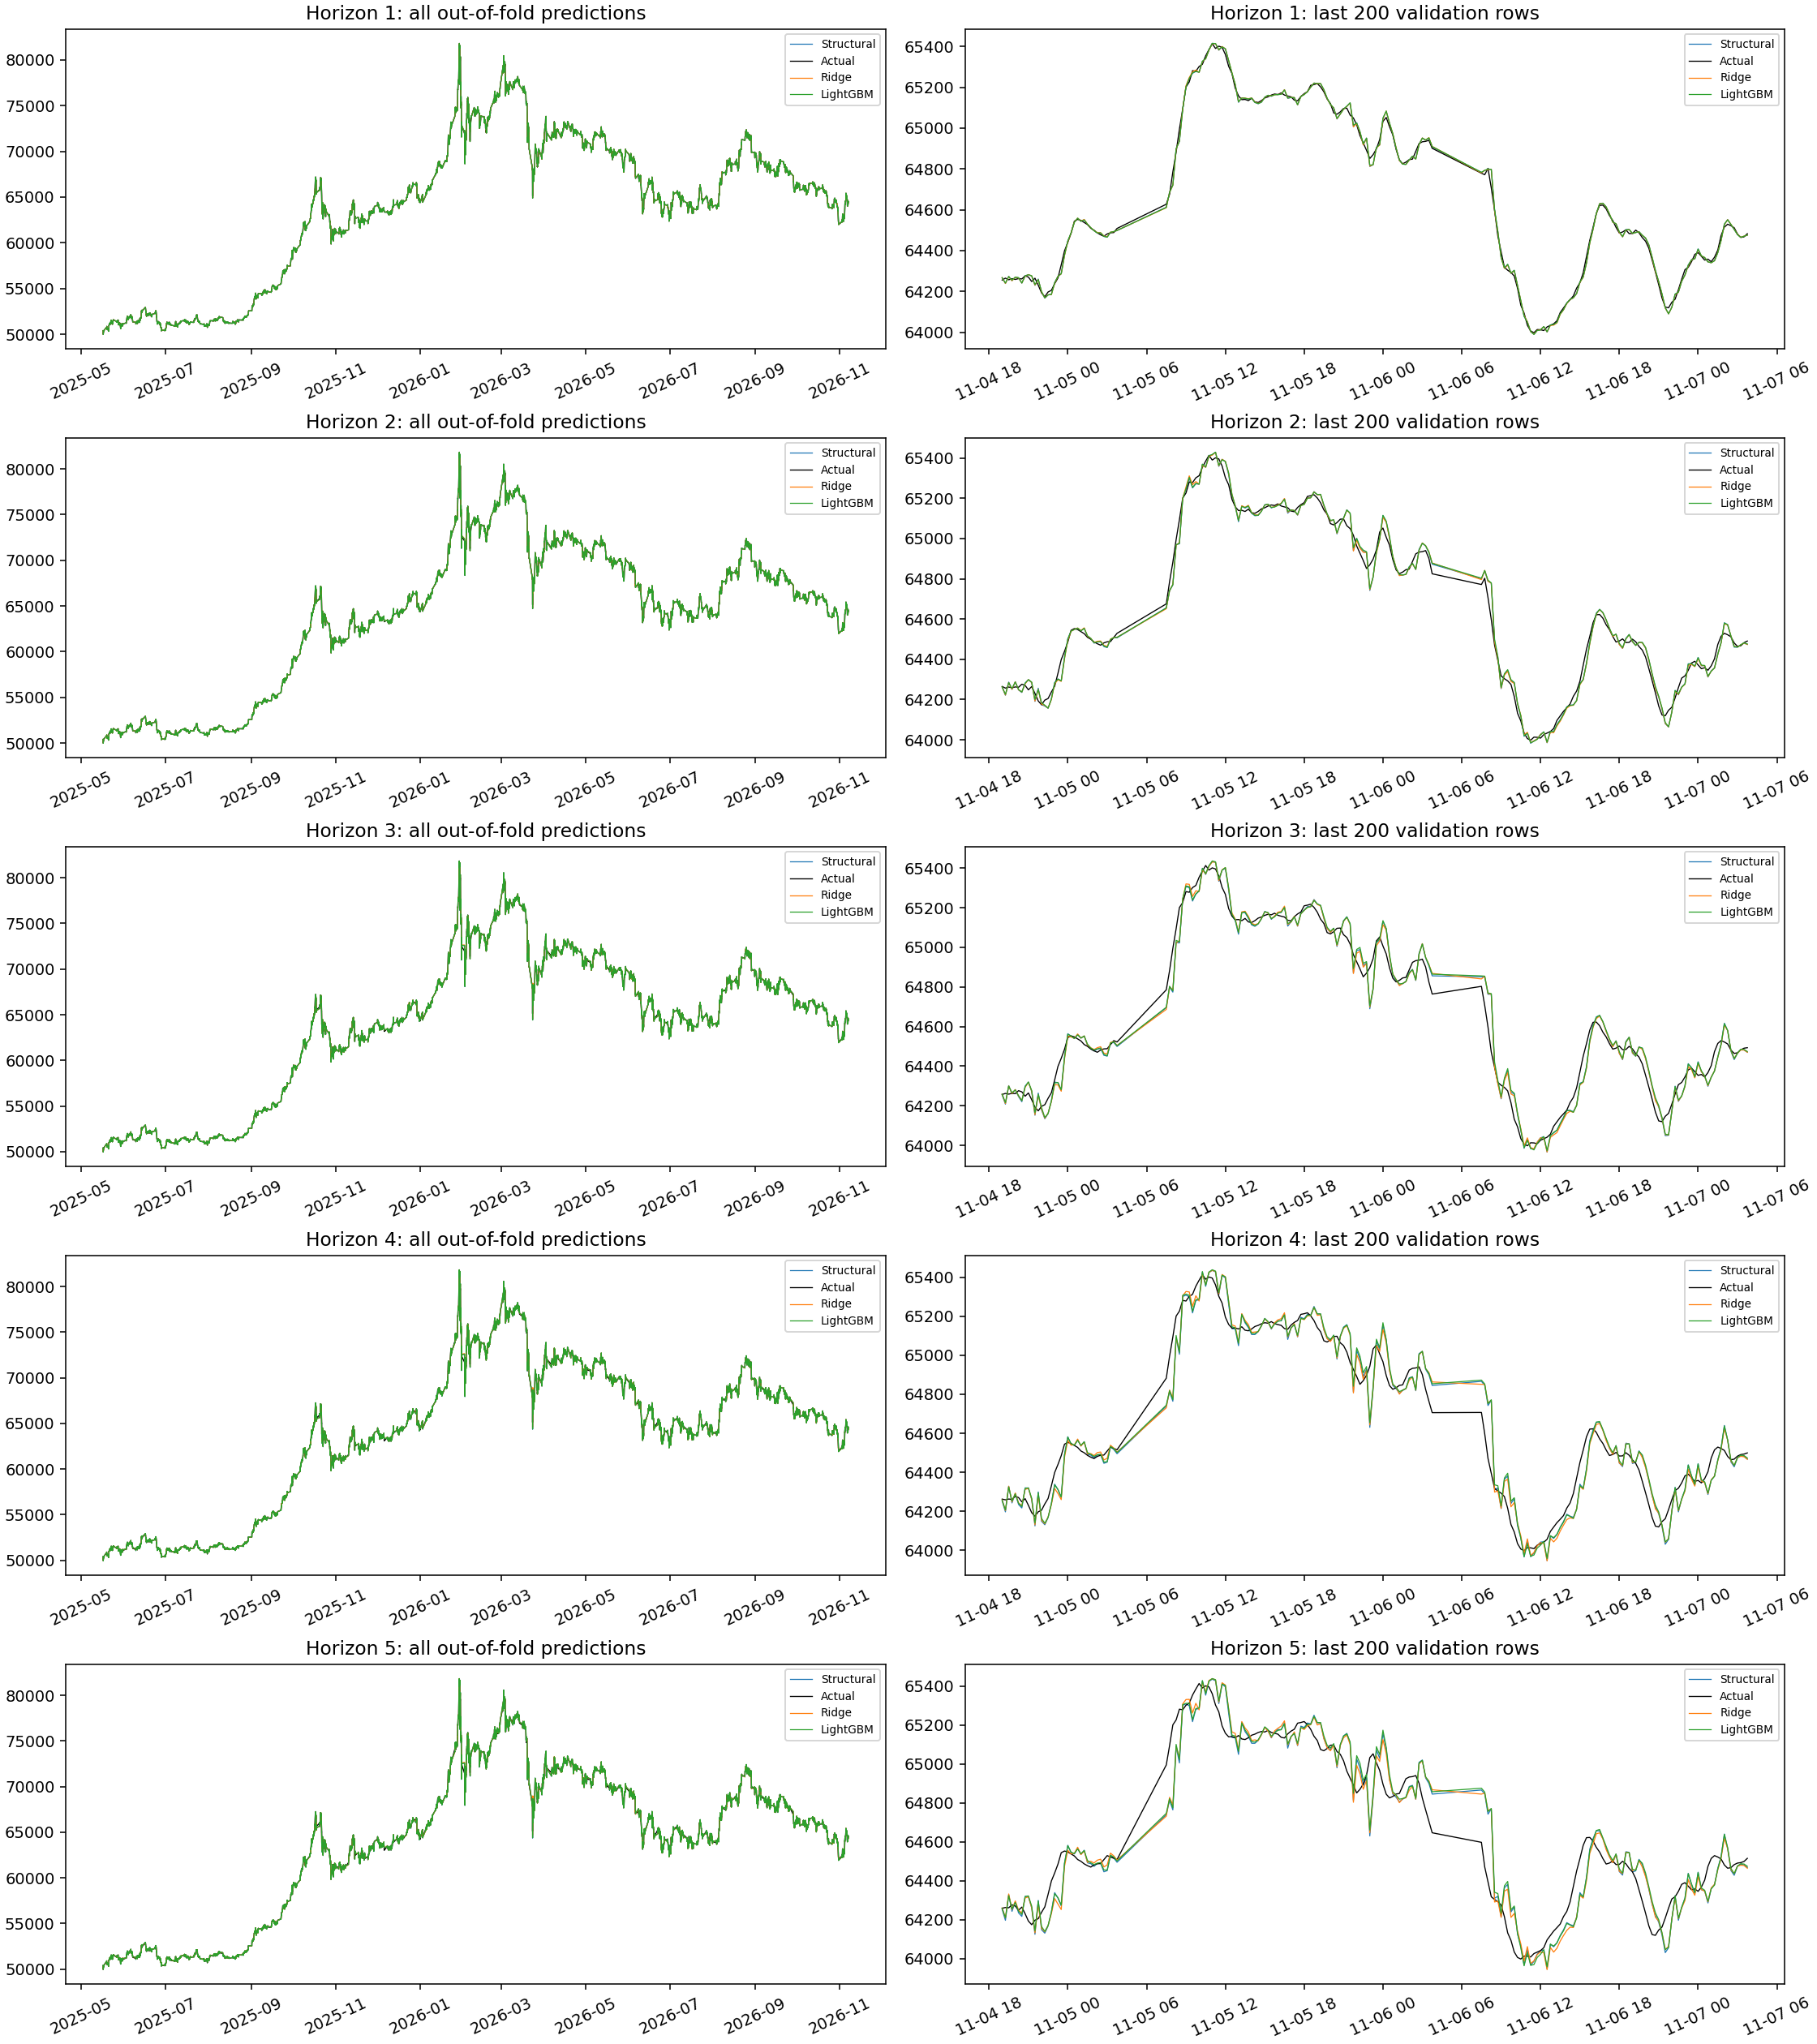

In [6]:
display(Image(filename=str(P/'actual_vs_predicted.png')))

## Interpretation
A positive lower gain bound indicates improvement versus the structural baseline on that development fold. Regression uses paired MSE gain; classification uses paired accuracy gain. No classification price forecast is fabricated. A model is marked accepted per fold only if its skill criterion and (for LightGBM) gain-diversity gate both pass. Final deployment acceptance requires fresh data and stability across folds. Average-fold summaries are descriptive, not pooled statistical tests. Confidence intervals are exploratory and unadjusted for multiple comparisons.